# Copula density-ratio model of Pareto-front selection

## Setup

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from scipy.special import digamma, logsumexp, rel_entr
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

DATA_DIR = Path('../nba_data')
PF_DIR = Path('../nba_game/data/unbiased_pf')
TRAIN_YEAR, TEST_YEAR = 2009, 2011   # season end years: fit on TRAIN_YEAR, predict TEST_YEAR
STATS = ['PTS', 'TRB', 'AST', 'STL', 'BLK']
VARS = [f'{s}/36' for s in STATS] + ['SAL/CAP']
EPS = 0.05                         # BLK has exact zeros, which a gamma cannot take

# tempering exponent α, chosen by 5-fold cross-validation over players
ALPHA_GRID = np.linspace(0.0, 2.0, 201)
CV_FOLDS, CV_SEED = 5, 0

# NBA salary cap ($M), keyed by season end year
SALARY_CAP = {2000: 34.0, 2001: 35.5, 2002: 42.5, 2003: 40.3, 2004: 43.9, 2005: 43.9, 2006: 49.5,
              2007: 53.1, 2008: 55.6, 2009: 58.7, 2010: 57.7, 2011: 58.0, 2012: 58.0, 2013: 58.7,
              2014: 58.7, 2015: 63.1, 2016: 70.0, 2017: 94.1, 2018: 99.1, 2019: 101.9, 2020: 109.1,
              2021: 109.1, 2022: 112.4, 2023: 123.7, 2024: 136.0, 2025: 140.6}
np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.precision', 4)
plt.rcParams['figure.dpi'] = 110

## Data

In [17]:
def load_year(year):
    df = pd.read_csv(DATA_DIR / f'nba_fantasy_{year}.csv')
    teams = pd.read_csv(PF_DIR / f'pf_indices_{year}.csv').values
    per36 = df[STATS].to_numpy(float) / df['MP'].to_numpy(float)[:, None] * 36
    V = np.column_stack([per36 + EPS, df['PREDICTED_SALARY'].to_numpy(float) / SALARY_CAP[year]])
    counts = np.bincount(teams.ravel(), minlength=len(df))
    df['SLOTS'], df['PROB'] = counts, counts / counts.sum()
    return df, V, counts, teams


df_tr, V_tr, c_tr, teams_tr = load_year(TRAIN_YEAR)
df_te, V_te, c_te, teams_te = load_year(TEST_YEAR)
p_tr, p_te = c_tr / c_tr.sum(), c_te / c_te.sum()

pd.DataFrame({y: {'players': len(df), 'teams': len(t), 'players on ≥1 team': int((c > 0).sum()),
                  'max team salary / cap': V[t, 5].sum(1).max()}
              for y, df, V, c, t in [(TRAIN_YEAR, df_tr, V_tr, c_tr, teams_tr), (TEST_YEAR, df_te, V_te, c_te, teams_te)]}).T

,players,teams,players on ≥1 team,max team salary / cap
2009,335.0,6542.0,182.0,0.9983
2011,350.0,9263.0,225.0,1.0000


## Gaussian copula with gamma marginals

In [43]:
def fit_gamma(x, w):
    xbar = np.sum(w * x)
    s = np.log(xbar) - np.sum(w * np.log(x))
    k = optimize.brentq(lambda k: np.log(k) - digamma(k) - s, 1e-6, 1e6)
    return k, xbar / k


def normal_scores(V, marg):
    U = np.column_stack([stats.gamma.cdf(V[:, j], a=k, scale=th) for j, (k, th) in enumerate(marg)])
    return stats.norm.ppf(np.clip(U, 1e-12, 1 - 1e-12))


def fit_copula(V, w=None):
    w = np.ones(len(V)) if w is None else np.asarray(w, float)
    w = w / w.sum()
    marg = [fit_gamma(V[:, j], w) for j in range(V.shape[1])]
    Z = normal_scores(V, marg)
    S = (Z * w[:, None]).T @ Z
    d = np.sqrt(np.diag(S))
    return {'marg': marg, 'R': S / np.outer(d, d)}


def logpdf(V, model):
    marg, R = model['marg'], model['R']
    log_marg = sum(stats.gamma.logpdf(V[:, j], a=k, scale=th) for j, (k, th) in enumerate(marg))
    Z = normal_scores(V, marg)
    _, logdet = np.linalg.slogdet(R)
    return log_marg - 0.5 * logdet - 0.5 * np.einsum('ij,jk,ik->i', Z, np.linalg.inv(R) - np.eye(len(R)), Z)


def log_ratio(V, f, f_w):
    # selection score r(x) = log f_w(x) - log f(x)
    return logpdf(V, f_w) - logpdf(V, f)

## Fits to the training year: f (pool) and f_w (front-weighted)

In [44]:
f = fit_copula(V_tr)
f_w = fit_copula(V_tr, p_tr)

marg = pd.concat({name: pd.DataFrame(m['marg'], index=VARS, columns=['shape k', 'scale θ'])
                  for name, m in [('f (pool)', f), ('f_w (front-weighted)', f_w)]}, axis=1)
for name in ['f (pool)', 'f_w (front-weighted)']:
    marg[(name, 'mean kθ')] = marg[(name, 'shape k')] * marg[(name, 'scale θ')]
marg.sort_index(axis=1, level=0, sort_remaining=False)

f (pool)                  f_w (front-weighted)                 
         shape k scale θ  mean kθ              shape k scale θ  mean kθ
PTS/36   10.4848  1.3331  13.9769              10.8412  1.3863  15.0288
TRB/36    5.2683  1.1849   6.2426               4.6222  1.6737   7.7363
AST/36    2.5145  1.1784   2.9630               1.4783  2.8924   4.2757
STL/36    7.3850  0.1516   1.1193               6.7103  0.2389   1.6032
BLK/36    1.3863  0.5807   0.8050               0.8216  1.6842   1.3838
SAL/CAP   2.4737  0.0409   0.1012               2.1815  0.0424   0.0924

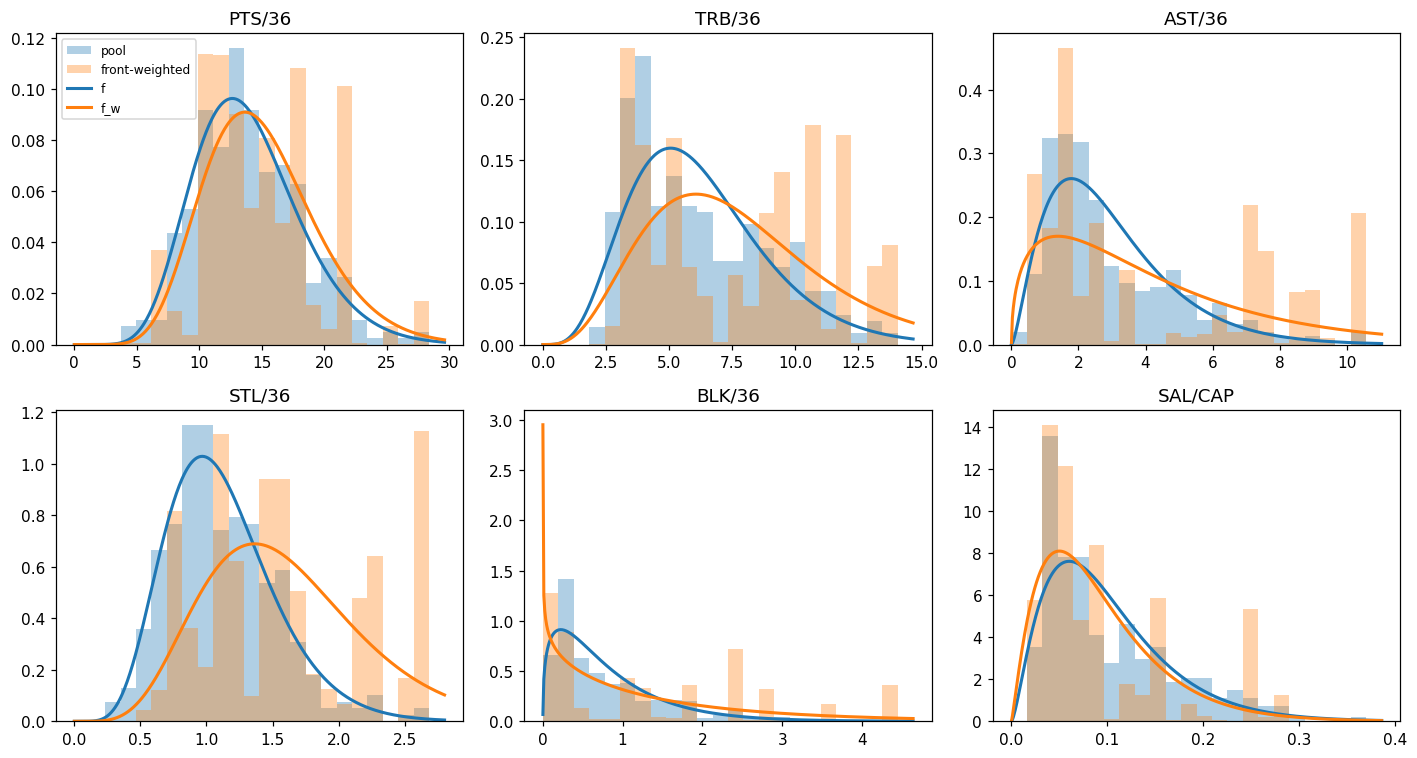

In [45]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j, (ax, name) in enumerate(zip(axes.flat, VARS)):
    x = V_tr[:, j]
    bins = np.linspace(0, x.max() * 1.05, 25)
    grid = np.linspace(1e-4, x.max() * 1.05, 400)
    ax.hist(x, bins=bins, density=True, alpha=0.35, color='C0', label='pool')
    ax.hist(x, bins=bins, weights=p_tr, density=True, alpha=0.35, color='C1', label='front-weighted')
    for model, c, lab in [(f, 'C0', 'f'), (f_w, 'C1', 'f_w')]:
        k, th = model['marg'][j]
        ax.plot(grid, stats.gamma.pdf(grid, a=k, scale=th), color=c, lw=2, label=lab)
    ax.set_title(name)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

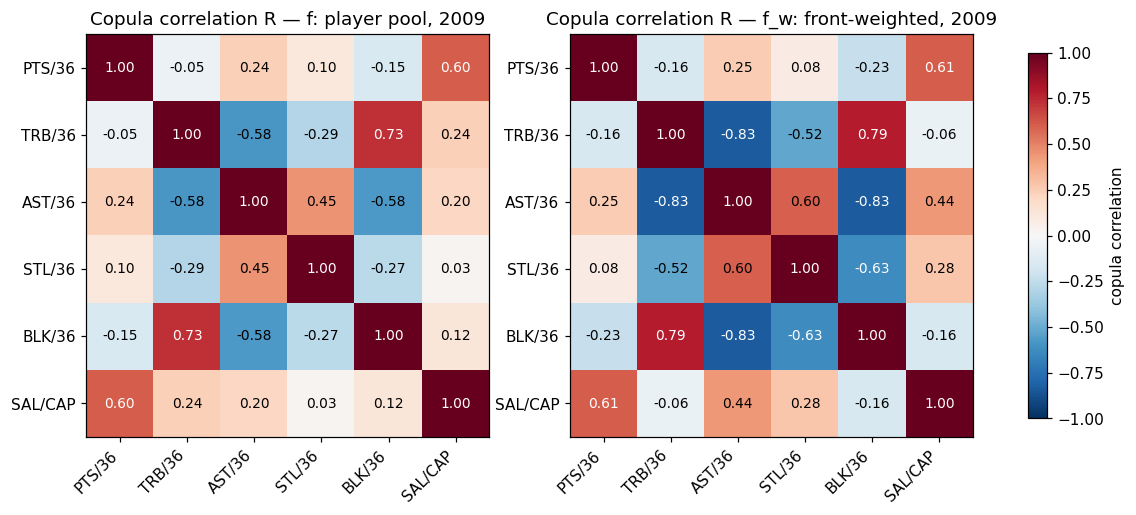

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, (model, title) in zip(axes, [(f, 'f: player pool'), (f_w, 'f_w: front-weighted')]):
    R = model['R']
    im = ax.imshow(R, cmap='RdBu_r', vmin=-1, vmax=1)
    for i in range(len(R)):
        for j in range(len(R)):
            ax.text(j, i, f'{R[i, j]:.2f}', ha='center', va='center', fontsize=9,
                    color='white' if abs(R[i, j]) > 0.6 else 'black')
    ax.set_xticks(range(len(VARS)), VARS, rotation=45, ha='right'); ax.set_yticks(range(len(VARS)), VARS)
    ax.set_title(f'Copula correlation R — {title}, {TRAIN_YEAR}')
fig.colorbar(im, ax=axes, shrink=0.8, label='copula correlation')
plt.show()

## Tempering exponent α: 5-fold cross-validation

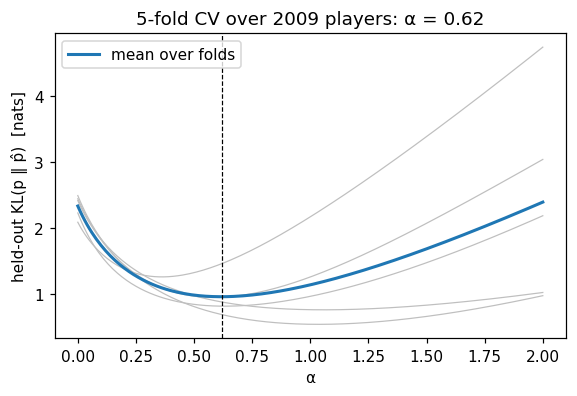

In [47]:
def kl(p, q):
    # KL(p || q) in nats; terms with p_i = 0 contribute 0
    return np.sum(rel_entr(p, q))


def softmax(s):
    return np.exp(s - logsumexp(s))


def alpha_cv(V, p, grid=ALPHA_GRID, folds=CV_FOLDS, seed=CV_SEED):
    D = np.zeros((folds, len(grid)))
    for k, (tr, te) in enumerate(KFold(folds, shuffle=True, random_state=seed).split(V)):
        r = log_ratio(V[te], fit_copula(V[tr]), fit_copula(V[tr], p[tr]))
        p_te = p[te] / p[te].sum()
        D[k] = [kl(p_te, softmax(a * r)) for a in grid]
    return grid[np.argmin(D.mean(0))], D


alpha, D_cv = alpha_cv(V_tr, p_tr)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(ALPHA_GRID, D_cv.T, color='0.75', lw=0.8)
ax.plot(ALPHA_GRID, D_cv.mean(0), color='C0', lw=2, label='mean over folds')
ax.axvline(alpha, color='k', ls='--', lw=0.8)
ax.set(xlabel='α', ylabel='held-out KL(p ‖ p̂)  [nats]', title=f'5-fold CV over {TRAIN_YEAR} players: α = {alpha:.2f}')
ax.legend(); plt.show()

## Prediction: training year and held-out test year

In [48]:
def predict(V, alpha):
    return softmax(alpha * log_ratio(V, f, f_w))


def js_bits(p, q):
    m = 0.5 * (p + q)
    return 0.5 * (kl(p, m) + kl(q, m)) / np.log(2)


def evaluate(p_hat, p, k=20):
    kl_uniform = np.log(len(p)) - stats.entropy(p)           # KL(p || uniform)
    return {'KL(p ‖ p̂) [nats]': kl(p, p_hat),
            'gap closed vs uniform': 1 - kl(p, p_hat) / kl_uniform,
            'JS [bits]': js_bits(p, p_hat),
            'TV distance': 0.5 * np.abs(p_hat - p).sum(),
            'Spearman ρ': stats.spearmanr(p_hat, p).statistic,
            'AUC (picked vs not)': roc_auc_score(p > 0, p_hat),
            f'top-{k} overlap': len(set(np.argsort(-p_hat)[:k]) & set(np.argsort(-p)[:k]))}


pred = {TRAIN_YEAR: predict(V_tr, alpha), TEST_YEAR: predict(V_te, alpha)}
pd.DataFrame({f'{TRAIN_YEAR} (train)': evaluate(pred[TRAIN_YEAR], p_tr),
              f'{TEST_YEAR} (held out)': evaluate(pred[TEST_YEAR], p_te)}).T.round(3)

,KL(p ‖ p̂) [nats],gap closed vs uniform,JS [bits],TV distance,Spearman ρ,AUC (picked vs not),top-20 overlap
2009 (train),0.480,0.794,0.178,0.349,0.739,0.853,14.0
2011 (held out),0.751,0.636,0.258,0.473,0.760,0.858,11.0


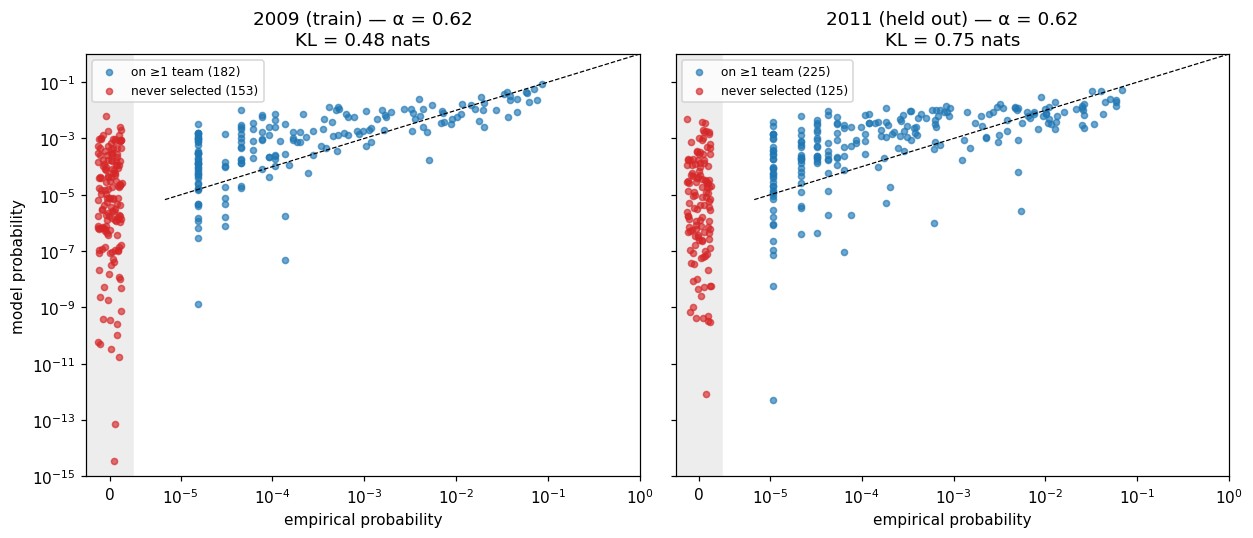

In [49]:
# shared axes for both seasons
pmin = min(p[p > 0].min() for p in (p_tr, p_te))
xmin = pmin / 1.6                                       # left edge of the nonzero region
zero_x = xmin / 4                                       # strip for players never selected
ymin = 10 ** np.floor(np.log10(min(pred[TRAIN_YEAR].min(), pred[TEST_YEAR].min())))
ticks = 10.0 ** np.arange(np.ceil(np.log10(xmin)), 1)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), sharey=True)
for ax, (y, p) in zip(axes, [(TRAIN_YEAR, p_tr), (TEST_YEAR, p_te)]):
    ph, pos = pred[y], p > 0
    ax.axvspan(zero_x / 1.8, zero_x * 1.8, color='0.93', zorder=0)
    ax.scatter(p[pos], ph[pos], s=16, alpha=0.65, color='C0', label=f'on ≥1 team ({pos.sum()})')
    ax.scatter(zero_x * np.exp(np.random.default_rng(0).uniform(-0.3, 0.3, (~pos).sum())), ph[~pos],
               s=16, alpha=0.65, color='C3', label=f'never selected ({(~pos).sum()})')
    ax.plot([xmin, 1], [xmin, 1], 'k--', lw=0.8)
    ax.set(xscale='log', yscale='log', xlim=(zero_x / 1.8, 1), ylim=(ymin, 1),
           xlabel='empirical probability',
           title=f'{y}{" (held out)" if y == TEST_YEAR else " (train)"} — α = {alpha:.2f}\nKL = {kl(p, ph):.2f} nats')
    ax.set_xticks([zero_x, *ticks], ['0'] + [f'$10^{{{int(np.log10(t))}}}$' for t in ticks])
    ax.minorticks_off()
    ax.legend(loc='upper left', fontsize=8)
axes[0].set_ylabel('model probability')
plt.tight_layout(); plt.show()

In [50]:
view = df_te[['PLAYER', *STATS, 'MP', 'PREDICTED_SALARY', 'PROB']].copy()
view['MODEL PROB'] = pred[TEST_YEAR]
view.sort_values('PROB', ascending=False).head(20)

,PLAYER,PTS,TRB,AST,STL,BLK,MP,PREDICTED_SALARY,PROB,MODEL PROB
75,Chris Paul,15.9,4.1,9.8,2.4,0.1,36.0,8.4,0.0682,0.0516
317,Joey Dorsey,3.1,4.4,0.6,0.6,0.4,12.1,1.9,0.0587,0.0230
187,Chris Andersen,5.6,4.9,0.4,0.5,1.3,16.3,4.1,0.0584,0.0147
134,Anthony Randolph,7.6,4.0,0.8,0.6,0.6,14.8,5.6,0.0582,0.0200
154,Darko Miličić,8.8,5.2,1.5,0.8,2.0,24.4,4.9,0.0501,0.0259
232,Tony Allen,8.9,2.7,1.4,1.8,0.6,20.8,3.0,0.0448,0.0200
80,Tyrus Thomas,10.2,5.5,0.7,0.7,1.6,21.0,8.1,0.0423,0.0076
165,DeJuan Blair,8.3,7.0,1.0,1.2,0.5,21.4,4.6,0.0404,0.0472
30,Steve Nash,14.7,3.5,11.4,0.6,0.1,33.3,11.3,0.0334,0.0032
57,Rajon Rondo,10.6,4.4,11.2,2.3,0.2,37.2,9.6,0.0321,0.0465
